In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [3]:
df = pd.read_csv("datasets/creditcard/creditcard.csv")

## Preprocessing Functions

In [4]:
def cat_summary(dataframe, col_name, plot=False):
    print(pd.DataFrame({col_name: dataframe[col_name].value_counts(),
                       "Ratio": 100 * dataframe[col_name].value_counts() / len(dataframe)}))
    print("##########################################")
    if plot:
        sns.countplot(x=dataframe[col_name], data=dataframe)
        plt.show()

In [5]:
def check_df(dataframe, head=5):
    print("##################### Shape #####################")
    print(dataframe.shape)
    print("##################### Types #####################")
    print(dataframe.dtypes)
    print("##################### Head #####################")
    print(dataframe.head(head))
    print("##################### Tail #####################")
    print(dataframe.tail(head))
    print("##################### NA #####################")
    print(dataframe.isnull().sum())
    print("##################### Quantiles #####################")
    numeric_columns = dataframe.select_dtypes(include=[np.number]).columns
    print(dataframe[numeric_columns].quantile([0, 0.05, 0.50, 0.95, 0.99, 1]).T)


In [6]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    print(dataframe[numerical_col].describe(quantiles).T)

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)

In [7]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit


In [8]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    # Aykırı değerleri boolean mask ile belirle
    outlier_mask = (dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)
    # Herhangi bir True değeri var mı diye kontrol et
    return outlier_mask.any()

In [9]:
def replace_with_thresholds(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    dataframe.loc[(dataframe[col_name] < low_limit), col_name] = low_limit
    dataframe.loc[(dataframe[col_name] > up_limit), col_name] = up_limit


In [10]:
def correlation_matrix(dataframe, cols, figsize=(12,10), font_size=10, annot_size=8):
    """
    Veri çerçevesi için gelişmiş korelasyon matrisi görselleştirmesi.

    Parameters:
    -----------
    dataframe : pandas DataFrame
        Analiz edilecek veri çerçevesi
    cols : list
        Korelasyon matrisi için kullanılacak kolonlar
    figsize : tuple, default=(12,10)
        Görselleştirme boyutu
    font_size : int, default=10
        Eksen etiketlerinin yazı boyutu
    annot_size : int, default=8
        Korelasyon değerlerinin yazı boyutu
    """

    # Figure boyutunu ayarla
    plt.figure(figsize=figsize)

    # Korelasyon matrisini hesapla
    corr_matrix = dataframe[cols].corr()

    # Maske oluştur (opsiyonel - üst üçgeni gizlemek için)
    # mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Isı haritası oluştur
    sns.heatmap(corr_matrix,
                annot=True,                 # Değerleri göster
                fmt='.2f',                  # Değerleri 2 ondalık basamakla göster
                cmap='RdBu_r',             # Renk paleti
                center=0,                   # Renk merkezini 0'a ayarla
                square=True,                # Kare hücreler
                linewidths=0.5,             # Hücre çizgi kalınlığı
                annot_kws={'size': annot_size},  # Korelasyon değerlerinin yazı boyutu
                cbar_kws={'shrink': .8},    # Renk çubuğu boyutu
                linecolor='white')          # Hücre çizgi rengi

    # Grafik özelliklerini ayarla
    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)
    plt.title('Değişkenler Arası Korelasyon Matrisi', pad=20, fontsize=font_size+2)

    # Layout'u düzenle
    plt.tight_layout()

    # Göster
    plt.show(block=True)

In [11]:
def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    #numeric olup kategorik olan değişkenler
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != "O"]
    #kategorik olup kardinalitesi yüksek olan değişkenler
    cat_but_car = [col for col in dataframe.columns if dataframe[col].dtypes == "O" and dataframe[col].nunique() > car_th]
    cat_cols += num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O" and col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f"cat_cols: {len(cat_cols)}")
    print(f"num_cols: {len(num_cols)}")
    print(f"cat_but_car: {len(cat_but_car)}")
    print(f"num_but_cat: {len(num_but_cat)}")

    return cat_cols, num_cols, cat_but_car


# Case Nedir?

Kredi kartı şirketlerinin, müşterilerin satın almadıkları ürünler için ücretlendirilmemesi adına dolandırıcılık işlemlerini tanımaları önemlidir.

Bu veri seti, Eylül 2013'te Avrupa kart sahipleri tarafından gerçekleştirilen kredi kartı işlemlerini içermektedir. Veri setinde 284.807 işlemin 492'si dolandırıcılık olarak sınıflandırılmıştır. Bu veri seti, yüksek derecede dengesizdir; olumlu sınıf (dolandırıcılıklar), tüm işlemin %0.172 sini oluşturmaktadır.

Bu veri seti, yalnızca PCA dönüşümü sonucu elde edilen sayısal girdi değişkenleri içermektedir. Ancak, gizlilik sebepleriyle orijinal özellikler ve veri hakkında daha fazla bilgi sağlayamamaktayız. V1, V2, .... V28 özellikleri PCA ile elde edilen temel bileşenlerdir. PCA ile dönüştürülmemiş tek özellikler 'Zaman've 'Tutar'dır. 'Zaman' özelliği, her bir işlem ile veri setindeki ilk işlem arasındaki geçen süreyi (saniye cinsinden) gösterirken, 'Tutar' özelliği işlem tutarını belirtmektedir. Bu özellik, örnek bağımlı maliyet hassas öğrenme için kullanılabilir. 'Sınıf' özelliği, dolandırıcılık durumunda 1, aksi taktirde 0 değerini alan yanıt değişkendir.

Sınıf dengesizliği oranı göz önüne alındığında, doğruluğun Precision-Recall eğrisi altındaki allan (AUPRC) ile ölçülmesini önermekteyiz. Karışıklık matrisindeki doğruluk, dengesiz sınıflandırma için anlamlı değildir.

- Veri Seti Hakkında:
    - Eylül 2013'te Avrupa'da gerçekleşen kredi kartı işlemlerini içeriyor
    - Toplam 284.80 işlem var
    - Bunların sadece 492 si (%0.172) dolandırıcılık

- Veri Özellikleri:
    - Çoğu özellik (V1'den V28'e kadar) PCA dönüşümü sonucu elde edilmiş temel bileşenlerdir
    - Sadece 'Zaman' ve 'Tutar' özellikleri orijinal haliyle korunmuş
    - 'Sınıf' değişkeni dolandırıcılık durumunu gösteriyor (1: Dolandırıcılık, 0: Normal)

- Önemli Noktalar:
    - Veri seti oldukça dengesiz (çok az sayıda dolandırıcılık vakası var)
    - Bu nedenle, normal doğruluk ölçümü yerine

### Neden confisuon matrix tek başına yeterli olmaz?

- Dengesiz veri setlerinde, sınıflar arasında büyük bir dengesizlik olduğunda, confisuon matrix'ten üretilen accuracy gibi metrikler yanıltıcı olabilir. Örneğin, tüm işlemleri "normal" olarak tahmin eden bir model, accuracy açısından çok yüksek bir değer alabilir, ancak bu model dolandırıcılıkları hiç tespit edemez

- AUPRC (Area Under Precision-Recall Curve):
    - Mantık: Precision ve recall'un farklı threshold değerlerinde nasıl değiştiğini gösterir. Dengesiz veri setlerinde, ROC eğrisine göre daha anlamlı olabilir çünkü pozitif sınıfın tespitine odaklanır.

## Dikkat edilmesi gereken kısımlar

- False Negatives(FN): Dolandırıcılık işlemlerini kaçırmak genellikle daha maliyetlidir. Bu yüzden recall'un yüksek olması önemlidir.

- False Positives (FP): Yanlış alarm sayısını azaltmak için precision'ın yüksek olması istenir.

- Threshold ayarlaması: Modelin tahminlerini sınıflandırmak için kullanılan threshold değeri, precision ve recall dengesini etkiler. Bu yüzden threshold optimizasyonu yapılabilir.

#### Özet
- Confusion matrix ve türetilen metrikler, modelin performansını anlamak için güçlü araçlardır. Ancak, dengesi veri setlerinde, bu metriklerin doğru bir şekilde yorumlanması ve iş problemine uygun metriklerin seçilmesi önemlidir. Dolandırıcılık tespiti gibi kritik alanlarda, precision ve recall dengesine dikkat etmek ve işin maliyetlerini göz önünde bulundurmak gerekir.

## Imbalanced Datasets

Deneysel olarak, en az %25 veri oranları performansı büyük ölçüde etkilememektedir. Ancak oran daha da küçüldüğünde bu durum geçerliliğini yitirir.

Çok küçük sınıf oranları içeren veri setlerinden kaynaklanan zorluklar 3 ayrı alanda ortaya çıkar:

    - Düşük örneklemeli sınıflar için modelleme ve öğrenme özelliklerinin korelasyonunu sağlamak

    - İlgili özelliklerin sınıf ayrımını tespit etmek, yani her sınıfa özgü olan ilgili özelliklerin belirlenmesi

    - Genellikle benzer sınıf boyutları için tasarlanmış "standart" değerlendirme metriklerine büyük bir önyargı eklenmesi


Bu sorunlar, aşağıdaki yöntemlerden biriyle hafifletilebilir:

    - Model düzeyinde: Modeller, daha küçük temsilci sınıflara daha fazla ağırlık verecek şekilde değiştirilerek, eğitim tahminlerindeki hataları daha ağır şekilde cezalandırabilir
    
    - Değerlendirme düzeyinde: Sınıf dengesini dikkate alan alternatif değerlendirme metrikleri kullanılmalıdır --- bu, yalnızca performans değerlendirme sorununu çözer, model sınıflandırmasının daha iyi olmasını 
    sağlamaz

    - Veri düzeyinde: Alternatif olarak, verinin kendisi dönüştürülebilir. Akıllıca yapıldığında, yeni örnekler eklenerek modellerin bu sınıfları daha iyi modellemesi sağlanabilir. Bu yöntemler, veri örnekleme yöntemi olarak adlandırılır.

# Dengesiz verileri yönetmek için en iyi 6 veri örnekleme yöntemi
- Veri örnekleme, bir veri kümesini (özellikler değil, örnekler açısından) dönüştüren algoritmalar sınıfını ifade eder

## Random Under Sampler
- Random Under Sampler, en yaygın örnekleme yöntemlerinden biridir ve daha büyük sınıfların verilerini en basit şekilde azaltır; her sınıftan mevcut örnekler seçer. Seçilen örnek sayısı, kabul edilebilir bir sınıf dengesi eşiği ile tanımlanır ve bu nedenle değişkendir.

 Genel olarak RU, verilerin yapay olarak üretilmediğini ve elde edilen verilerin tamamının orijinal veri kümesinin bir alt kümesi olduğunu garanti eder. Ancak, yüksek dengesizlik durumlarında, bu genellikle mevcut eğitim verilerinin büyük bir kaybına yol açar ve nihayetinde model performansının düşmesine neden olur.

## Random Over Sampler

- RU'nun bir alternatifi olan Random Over-Sampler (RO) algoritması, benzer bir tekniği ters yönde uygular. Büyük sınıflar azaltılmak yerine, küçük sınıflar aşırı örneklendirilerek sınıf büyüklükleri dengelenir. Aşırı örneklendirme ile örnekler birden fazla kez görünebilir.

- RO, veri silme sorununu çözer (RU' dan farklı olarak). Ancak, bu yöntem veri setinde örneklerin tekrar görünmesiyle başka bir yanlılık da ortaya çıkar. Bu durum, tekrar eden örneklerin tam özellik değerlerine odaklanma yanlılığı yaratır ve ilgili ayırıcı bölgeler ile sınırları bulmaktan uzaklaşılır.

# Synthetic Minority Oversampling Technique (SMOTE)

- SMOTE, daha küçük sınıfların aşırı örneklemek için kullanılan bir algoritmadır. SMOTE'un temel fikri, üretilen örneklerin mevcut gözlemlerden oluşturulması gerektiği, ancak bunların aynı olmaması gerektiğidir. SMOTE, azınlık sınıfına yeni örnekler üretmek için şu algoritmayı kullanır:

    1. Orijinal eğitim veri seti üzerinde bir SVM sınıflandırıcısı eğitildikten sonra, sınır bölgeleri destek vektörleriyle yaklaşık olarak belirlenir.
    
    2. Hesaplandıktan sonra, bu sınırın yanındaki örnekler sentezlenir.
    
    3. Aynı azınlık sınıfından rastgele bir çift nokta seçilir. x_i ve x_j. Burada x_j, x_i'nin k komşusundan seçilir.

    4. U[0,1] aralığından rastgele bir değer t seçilir.

    5. Yeni bir örnek x = t * x_i + (1-t) * x_j olarak oluşturulur.

    6. Aşırı örnekleme oranı eşiğine göre yeterli sayıda örnek elde edilene kadar bu işlem tekrarlanır.

SMOTE, çeşitli uygulamalarda yaygın olarak kullanılmış ve büyük başarılar elde etmiştir. En yaygın aşırı örnekleme mekanizmalarından biri olmayı sürdürmekte ve her birinin kendine özgü güçlü ve zayıf yönleri olan birçok varyantın ortaya çıkmasına neden olmuştur. Ancak, SMOTE'un hiçbir varyantının sürekli olarak etkisini ve performansını artırdığı gösterilmemiştir.

# Borderline SMOTE

- SMOTE algoritmasının varyantıdır ve şu varsayımı yapar:
    - "Karar sınırına en yakın örnekler daha önemlidir"

- Bu nedenle, Borderline SMOTE, iki sınıf arasındaki karar sınırı boyunca sentetik veriler üretir. Bu senaryoda, bir karar sınırı, bir örneğin K-komşusundaki yanlış sınıflandırmalara bakılarak belirlenir. Eğer K-en yakın nokta setinde birden fazla sınıf bulunuyorsa, o örnek karar sınırına yakın olarak kabul edilir.

# SVM-SMOTE

- SVM-SMOTE, BorderlineSMOTE ile benzerlik gösterir, ancak karar sınırlarının ve bir sınıra en yakın noktaların belirlenmesi açısından önemli bir fark vardır. SVM-SMOTE, çoklu sınıflandırmanın nerede yapıldığını belirlemek için SVM algoritmasının kullanılmasını önerir.

- Sınır bölgeleri, orijinal eğitim veri kümesi üzerinde SVM sınıflayıcısı eğitildikten sonra destek vektörleriyle yaklaşık olarak belirlenir. Hesaplandıktan sonra, tahmin edilen sınırın yanındaki örnekler sentezlenir.

## Örnekleme teknikleri karşılaştırılması

- Bir örnekleme yönteminin kullanımının değerlendirilmesi, yalnızca örnekleme sonuçlarının başka bir göreve sunulmasında sonra belirlenebilir. Bunun nedeni, örneklenen verilerin çıktısının orijinak veriden daha iyi olup olmadığını belirleyecek net bir mekanizmanın olmamasıdır. Tanım gereği, yeni veri, sınıflandırma performanısını artırıyorsa daha iyidir. Bu bağlamda, aşırı örnekleme yöntemlerinin karşılaştırılması yalnızca yeniden örnekleme sonrası doğruluk, f1 skoru, geri çağırma ve kesinlik gibi ölçütler üzerinden gerçekleştirilebilir. Önemli bir gözlem, farklı örneklemelerin farklı modeller açısından performans sıralamasında farklılık gösterebileceğidir.

# ADASYN

- Adaptif Sentetik Örnekleme (ADASYN), SMOTE'un bir başka varyantıdır. ADASYN, puan tahsisi olasılığına bir öncelik ekler, yani sınır karar bölgesine odaklanmak yerine, verinin yoğunluğunu aşırı örnekleme için ilgili örnekleri belirlemede belirleyici bir faktör olarak dikkate alır.

- Seçim olasılığı, azınlık sınıfının yoğunluğu ile ters orantılıdır; bu sayede, azınlık örneklerinin yoğunluğunun düşük olduğu yerlerde daha fazla sentetik veri üretilir (ve tersi)

In [12]:
check_df(df)

##################### Shape #####################
(284807, 31)
##################### Types #####################
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object
##################### Head #####################
   Time     V1     V2    V3     V4     V5     V6     V7     V8     V9    V10    V11    V12    V13    V14    V15    V16    V17    V18    V19    V20    V21    V22    V23    V24    V25    V26    V27    V28  Amount  Class
0 0.000 -1.360 -0.073 2.536  1.378 -0.338  0.462

In [13]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'], dtype='object')

In [14]:
df.Time.describe()

count   284807.000
mean     94813.860
std      47488.146
min          0.000
25%      54201.500
50%      84692.000
75%     139320.500
max     172792.000
Name: Time, dtype: float64

In [15]:
# Basit stil ayarı
plt.style.use('default')

# Türkçe karakter desteği için
plt.rcParams['font.family'] = 'DejaVu Sans'

Feature Engineering

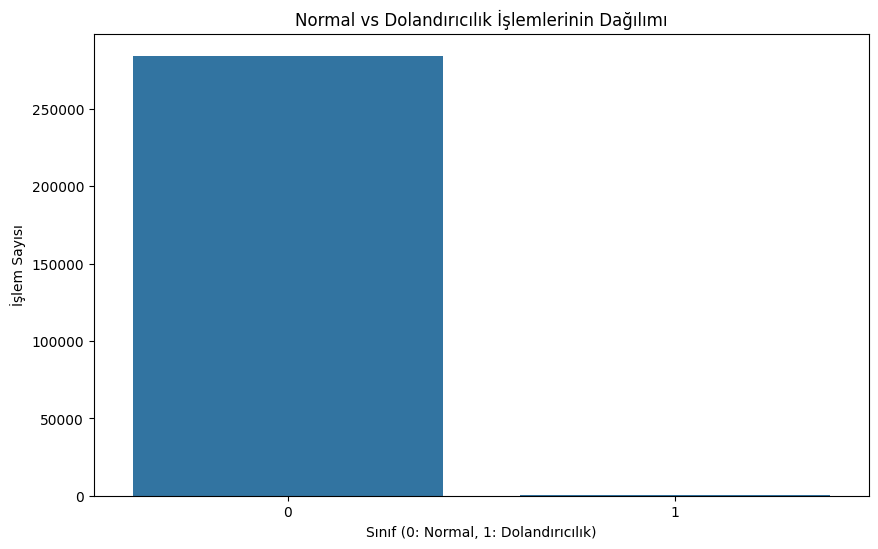

In [16]:
# Sınıf dağılımı görselleştirmesi
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Class')
plt.title('Normal vs Dolandırıcılık İşlemlerinin Dağılımı')
plt.xlabel('Sınıf (0: Normal, 1: Dolandırıcılık)')
plt.ylabel('İşlem Sayısı')
plt.show()

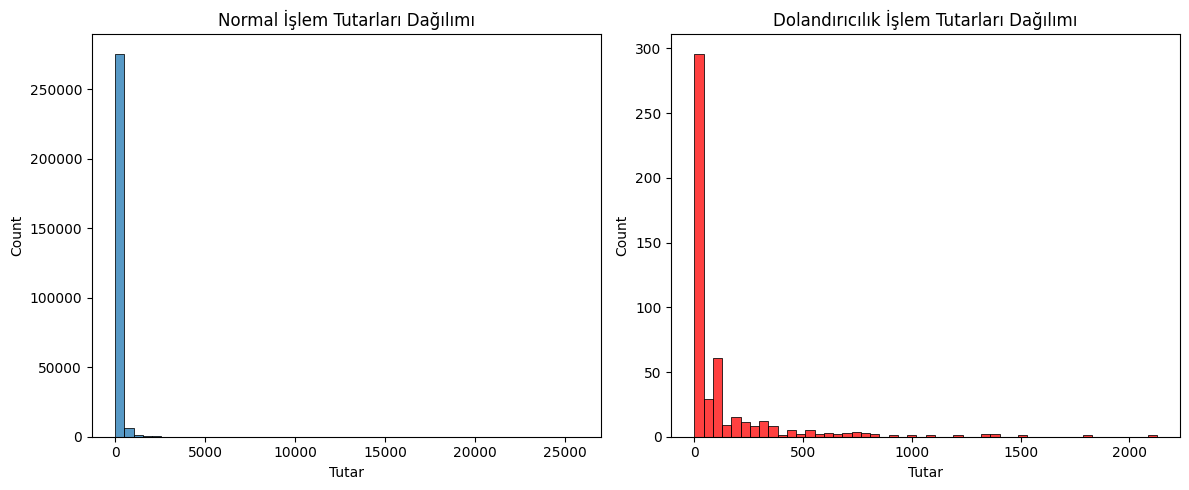

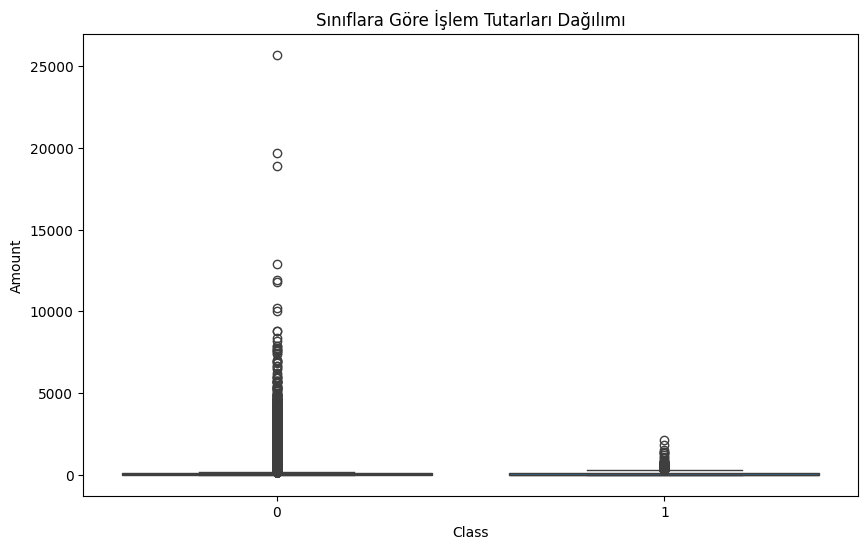

In [17]:
# İşlem tutarlarının dağılımı
plt.figure(figsize=(12, 5))

# Normal işlemler için histogram
plt.subplot(1, 2, 1)
sns.histplot(data=df[df['Class']==0], x='Amount', bins=50)
plt.title('Normal İşlem Tutarları Dağılımı')
plt.xlabel('Tutar')

# Dolandırıcılık işlemleri için histogram
plt.subplot(1, 2, 2)
sns.histplot(data=df[df['Class']==1], x='Amount', bins=50, color='red')
plt.title('Dolandırıcılık İşlem Tutarları Dağılımı')
plt.xlabel('Tutar')

plt.tight_layout()
plt.show()

# Box plot karşılaştırması
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Class', y='Amount')
plt.title('Sınıflara Göre İşlem Tutarları Dağılımı')
plt.show()


## Normal işlemlerin büyük çoğunluğu düşük tutarlı
## Yüksek tutarlı işlemler çok nadir

## Dolandırıcılık işlemlerinde yine frekans düşük tutarlarda
## Fakat normal işlemlere göre daha geniş bir tutar aralığına yayılmış


## Dolandırıcılar genellikle dikkat çekmemek için küçük tutarlı işlemler yapmayı
## tercih ediyorlar
## Sadece işlem tutarına bakarak dolandırıcılık tespiti yapmak yanıltıcı olabilir

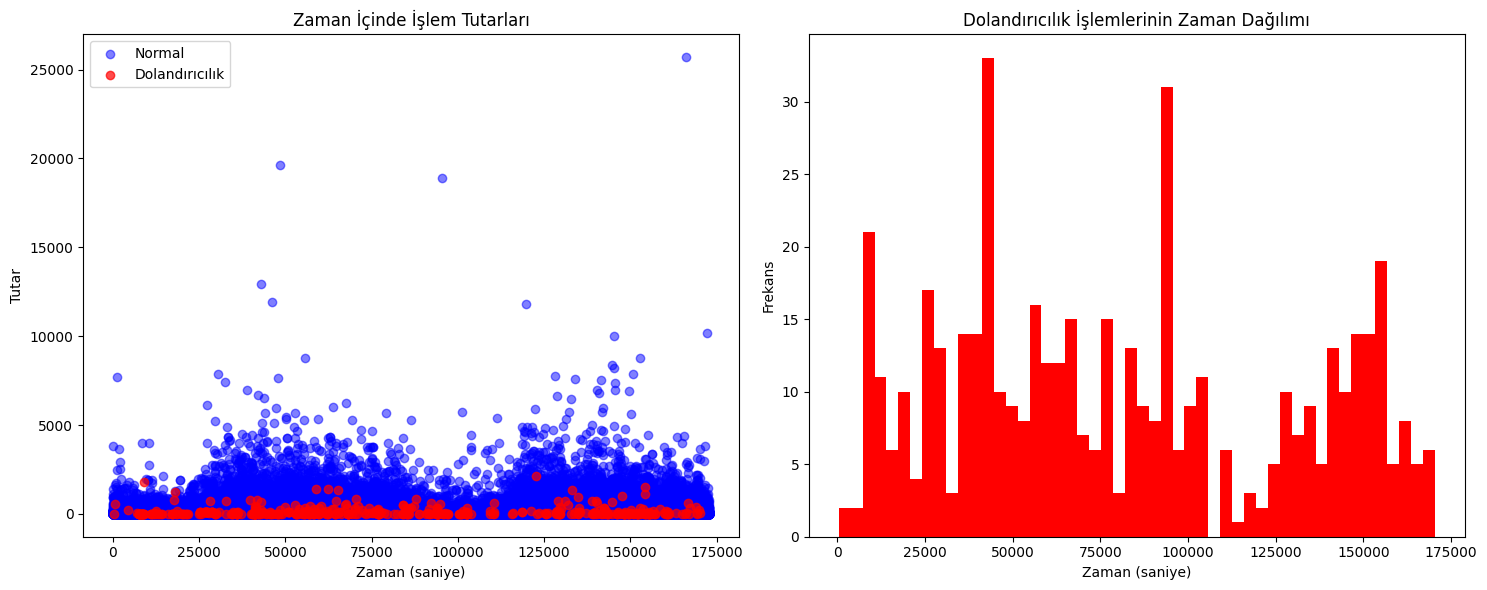

In [18]:
# Zaman serisi analizi
plt.figure(figsize=(15, 6))

# Tüm işlemlerin zaman dağılımı
plt.subplot(1, 2, 1)
plt.scatter(df[df['Class']==0]['Time'], df[df['Class']==0]['Amount'],
           alpha=0.5, label='Normal', color='blue')
plt.scatter(df[df['Class']==1]['Time'], df[df['Class']==1]['Amount'],
           alpha=0.7, label='Dolandırıcılık', color='red')
plt.title('Zaman İçinde İşlem Tutarları')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Tutar')
plt.legend()

# Dolandırıcılık işlemlerinin zaman dağılımı
plt.subplot(1, 2, 2)
plt.hist(df[df['Class']==1]['Time'], bins=50, color='red')
plt.title('Dolandırıcılık İşlemlerinin Zaman Dağılımı')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Frekans')

plt.tight_layout()
plt.show()


## Normal işlemler tüm zaman periyoduna yayılmış durumda
## İşlemlerin çoğu 5000 birimin altında yoğunlaşmış

# Sağdaki grafik
# İki belirgin pik noktası var
# Yaklaşık 50.000 saniye civarında
# Yaklaşık 100.000 saniye civarında
# Dolandırıcılık aktivitelerinin belirli zaman dilimlerinde
# yoğunlaştığını gözlemleyebiliriz


In [19]:
df['hour'] = df['Time'] // 3600

In [20]:
df['day'] = df['Time'] // (24 * 3600)

In [21]:
df.drop(columns=['Time'], inplace=True)


In [22]:
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'hour', 'day'], dtype='object')

In [23]:
df['log_amount'] = np.log1p(df['Amount'])

In [24]:
df['amount_hour_mean_diff'] = df.groupby('hour')['Amount'].transform('mean')
df['amount_hour_std_diff'] = df.groupby('hour')['Amount'].transform('std')
df['amount_from_mean'] = df['Amount'] - df['amount_hour_mean_diff']

In [25]:
# 3. İstatistiksel özellikler
v_cols = [f'V{i}' for i in range(1, 29)]
df['v_mean'] = df[v_cols].mean(axis=1)
df['v_std'] = df[v_cols].std(axis=1)

In [26]:
def analyze_data_quality(df):
    print("1. MISSING VALUE ANALİZİ")
    print("-----------------------")
    # Eksik değerlerin analizi
    missing_values = df.isnull().sum()
    missing_percentages = (missing_values / len(df)) * 100

    missing_df = pd.DataFrame({
        'Eksik Değer Sayısı': missing_values,
        'Eksik Değer Yüzdesi': missing_percentages
    })
    print(missing_df[missing_df['Eksik Değer Sayısı'] > 0])
    print("\n")

    print("2. AYKIRI DEĞER ANALİZİ")
    print("----------------------")

    # Sayısal kolonlar için aykırı değer analizi
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    outliers_summary = {}
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
        outliers_summary[col] = {
            'Aykırı Değer Sayısı': len(outliers),
            'Aykırı Değer Yüzdesi': (len(outliers) / len(df)) * 100,
            'Alt Sınır': lower_bound,
            'Üst Sınır': upper_bound,
            'Minimum': df[col].min(),
            'Maximum': df[col].max()
        }

    outliers_df = pd.DataFrame(outliers_summary).T
    print(outliers_df)

    # Görselleştirmeler
    plt.figure(figsize=(15, 5))

    # Amount için box plot
    plt.subplot(121)
    sns.boxplot(x=df['Amount'])
    plt.title('Amount - Box Plot')

    # Amount için histogram
    plt.subplot(122)
    sns.histplot(df['Amount'], bins=50)
    plt.title('Amount - Histogram')
    plt.show()

    # V1-V28 için box plot matrix
    plt.figure(figsize=(20, 15))
    v_cols = [f'V{i}' for i in range(1, 29)]
    df[v_cols].boxplot(figsize=(20, 10))
    plt.xticks(rotation=45)
    plt.title('V1-V28 Box Plots')
    plt.show()

    return outliers_df

1. MISSING VALUE ANALİZİ
-----------------------
Empty DataFrame
Columns: [Eksik Değer Sayısı, Eksik Değer Yüzdesi]
Index: []


2. AYKIRI DEĞER ANALİZİ
----------------------
                       Aykırı Değer Sayısı  Aykırı Değer Yüzdesi  Alt Sınır  Üst Sınır  Minimum   Maximum
V1                                7062.000                 2.480     -4.274      4.670  -56.408     2.455
V2                               13526.000                 4.749     -2.702      2.907  -72.716    22.058
V3                                3363.000                 1.181     -3.767      3.904  -48.326     9.383
V4                               11148.000                 3.914     -3.237      3.131   -5.683    16.875
V5                               12295.000                 4.317     -2.647      2.567 -113.743    34.802
V6                               22965.000                 8.063     -2.519      2.149  -26.161    73.302
V7                                8948.000                 3.142     -2.241      2.

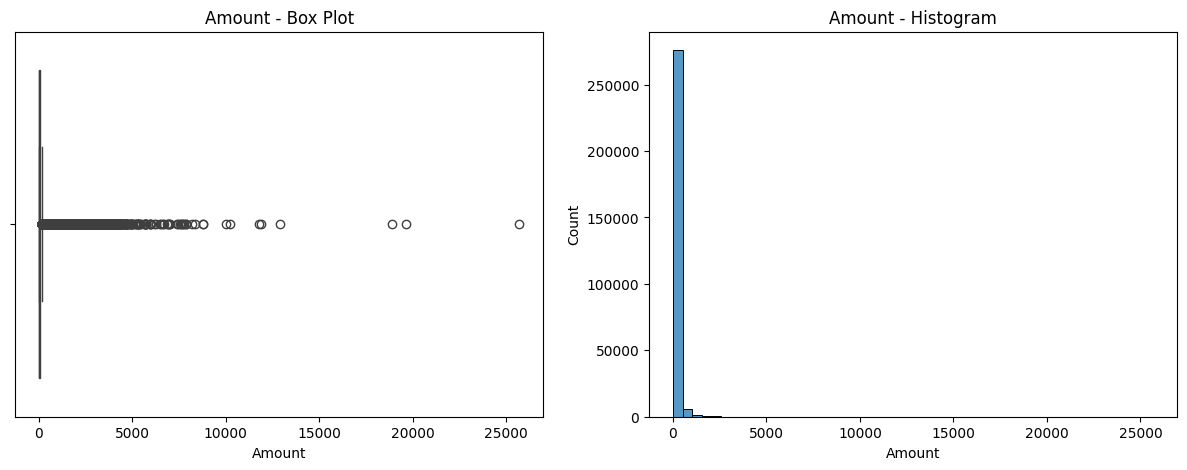

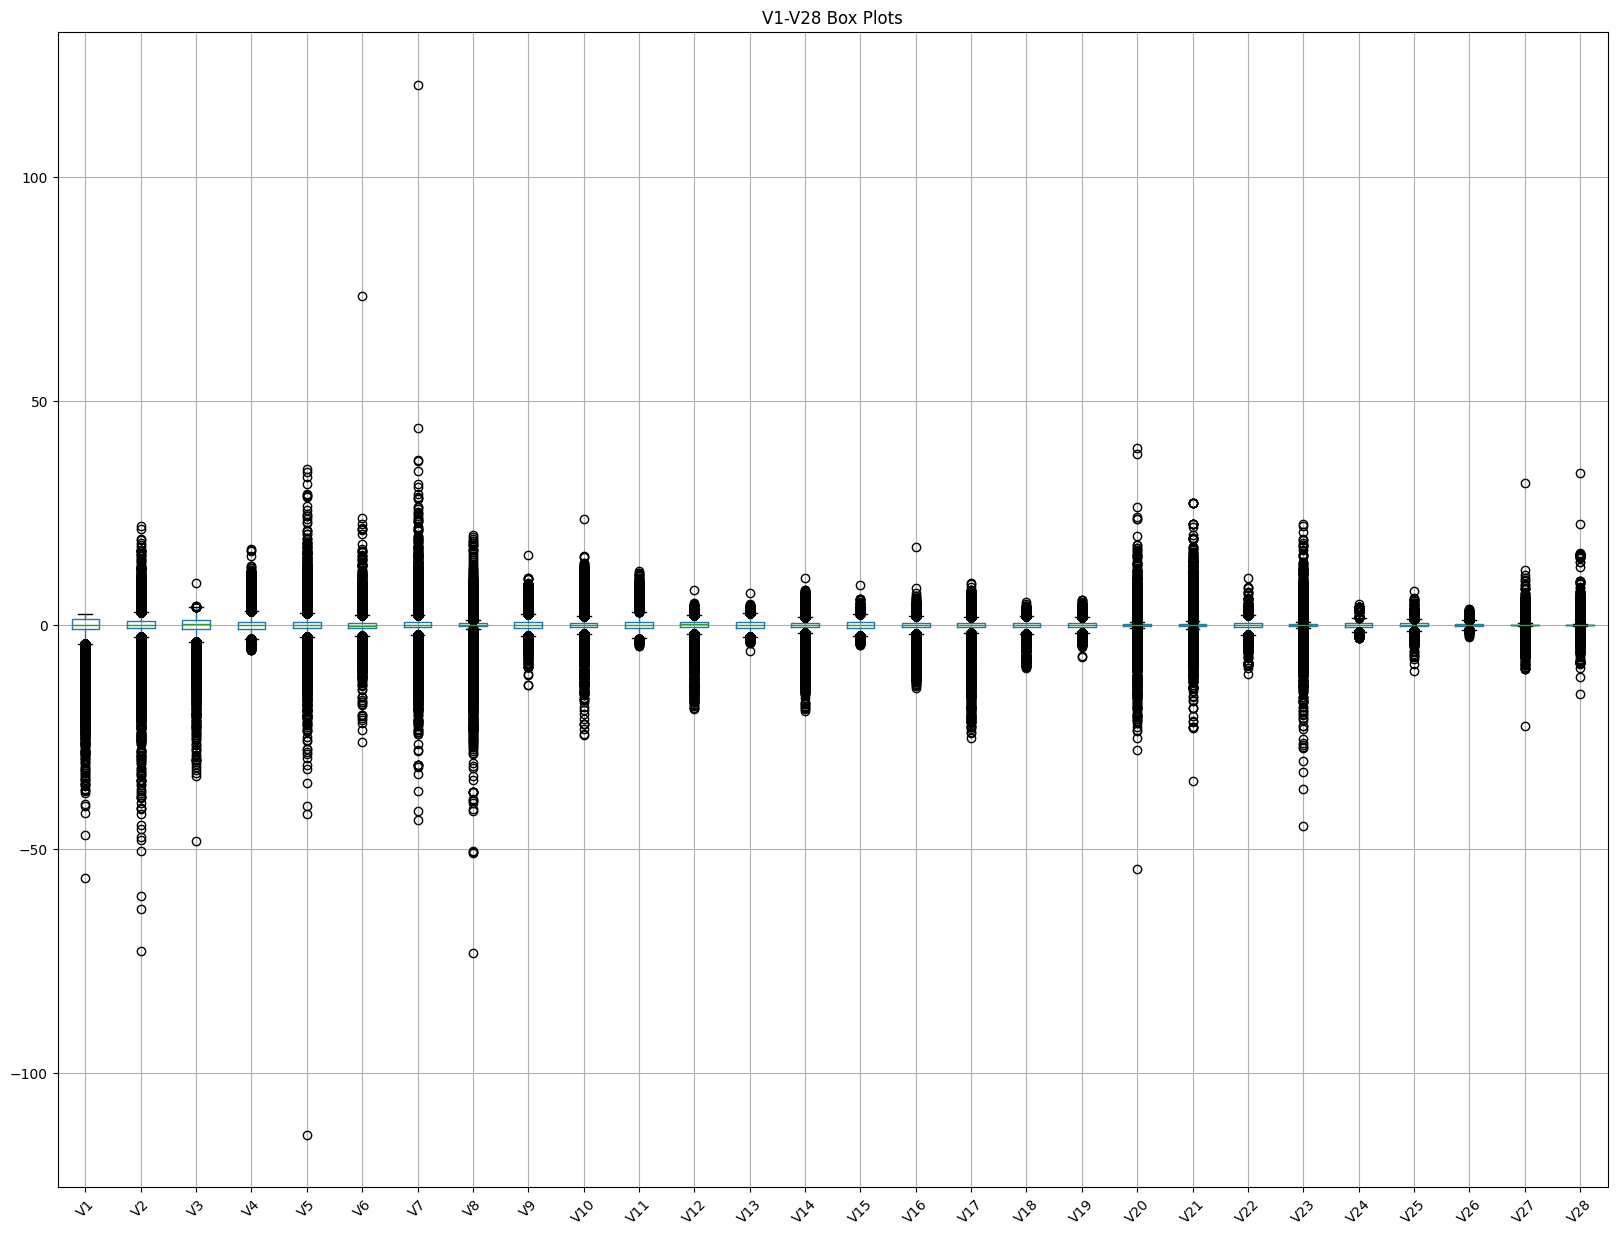

In [27]:
# Analizi çalıştırma
outliers_summary = analyze_data_quality(df)

In [28]:
# Aykırı değerler için sınıf bazlı analiz
def analyze_outliers_by_class(df):
    numeric_cols = ['Amount'] + [f'V{i}' for i in range(1, 29)]

    plt.figure(figsize=(15, 5))
    for i, col in enumerate(['Amount', 'V1', 'V2']):  # Örnek olarak birkaç değişken
        plt.subplot(1, 3, i+1)
        sns.boxplot(x='Class', y=col, data=df)
        plt.title(f'{col} by Class')
    plt.tight_layout()
    plt.show()

    # Her sınıf için aykırı değer oranları
    outlier_rates = {}
    for col in numeric_cols:
        outlier_rates[col] = {}
        for class_val in [0, 1]:
            class_data = df[df['Class'] == class_val][col]
            Q1 = class_data.quantile(0.25)
            Q3 = class_data.quantile(0.75)
            IQR = Q3 - Q1
            outliers = class_data[(class_data < (Q1 - 1.5 * IQR)) |
                                (class_data > (Q3 + 1.5 * IQR))]
            outlier_rates[col][f'Class_{class_val}_Outlier_Rate'] = len(outliers) / len(class_data)

    return pd.DataFrame(outlier_rates)

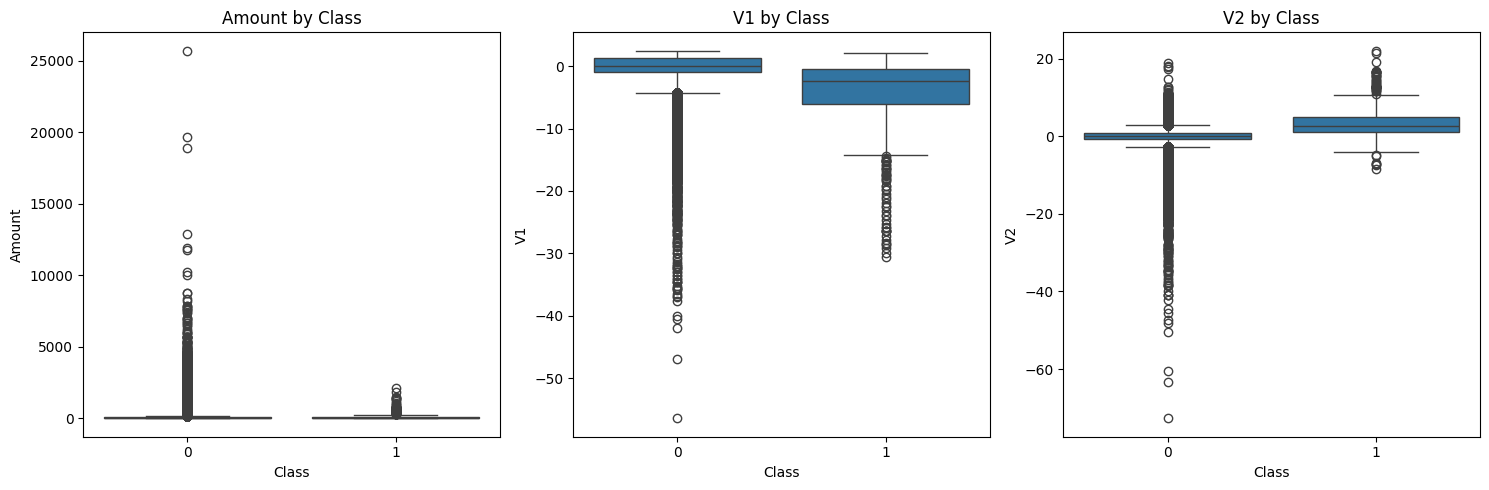


Sınıf Bazlı Aykırı Değer Oranları:
                      Amount    V1    V2    V3    V4    V5    V6    V7    V8    V9   V10   V11   V12   V13   V14   V15   V16   V17   V18   V19   V20   V21   V22   V23   V24   V25   V26   V27   V28
Class_0_Outlier_Rate   0.112 0.024 0.047 0.011 0.038 0.043 0.080 0.030 0.084 0.028 0.032 0.002 0.053 0.012 0.049 0.010 0.028 0.025 0.026 0.036 0.097 0.050 0.005 0.065 0.017 0.019 0.020 0.137 0.106
Class_1_Outlier_Rate   0.140 0.106 0.093 0.108 0.000 0.091 0.030 0.061 0.199 0.035 0.039 0.020 0.012 0.000 0.008 0.016 0.000 0.000 0.000 0.010 0.083 0.100 0.049 0.120 0.006 0.073 0.004 0.142 0.093


In [29]:
# Sınıf bazlı aykırı değer analizi
class_outliers = analyze_outliers_by_class(df)
print("\nSınıf Bazlı Aykırı Değer Oranları:")
print(class_outliers)

In [30]:
from scipy import stats

In [31]:
for col in df.columns:
    print(col, check_outlier(df,col))

V1 True
V2 True
V3 True
V4 True
V5 True
V6 True
V7 True
V8 True
V9 True
V10 True
V11 True
V12 True
V13 True
V14 True
V15 True
V16 True
V17 True
V18 True
V19 True
V20 True
V21 True
V22 True
V23 True
V24 True
V25 True
V26 True
V27 True
V28 True
Amount True
Class True
hour False
day False
log_amount True
amount_hour_mean_diff False
amount_hour_std_diff True
amount_from_mean True
v_mean True
v_std True


In [32]:
#for col in df.columns:
    #replace_with_thresholds(df,col)

In [33]:
for col in df.columns:
    print(col, check_outlier(df,col))

V1 True
V2 True
V3 True
V4 True
V5 True
V6 True
V7 True
V8 True
V9 True
V10 True
V11 True
V12 True
V13 True
V14 True
V15 True
V16 True
V17 True
V18 True
V19 True
V20 True
V21 True
V22 True
V23 True
V24 True
V25 True
V26 True
V27 True
V28 True
Amount True
Class True
hour False
day False
log_amount True
amount_hour_mean_diff False
amount_hour_std_diff True
amount_from_mean True
v_mean True
v_std True


In [34]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
#from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
#from cuml.ensemble import RandomForestClassifier

In [35]:
# Veri setini hazırlama
X = df.drop(['Class'], axis=1)  # Time'ı çıkarıyoruz
y = df['Class']

In [36]:
# Veriyi train, validation ve test olarak bölme
X_temp, X_test, y_temp, y_test = train_test_split(X, y,
                                                 test_size=0.2,
                                                 random_state=42,
                                                 stratify=y)

In [37]:
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,
                                                 test_size=0.25,
                                                 random_state=42,
                                                 stratify=y_temp)

In [38]:
# Veri ölçeklendirme
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [39]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
import time
import autosklearn.classification
import autosklearn.metrics

In [40]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)


In [41]:
automl = autosklearn.classification.AutoSklearnClassifier(
    time_left_for_this_task=1800,    # 30 dakika
    per_run_time_limit=180,          # Her model için 3 dakika
    memory_limit=10240,              # 10GB RAM limiti
    metric=autosklearn.metrics.average_precision,
    ensemble_kwargs={'ensemble_size': 1},
    resampling_strategy='cv',
    resampling_strategy_arguments={'folds': 3}
)

In [42]:
# Eğitim süresini ölçme
start_time = time.time()

# Modeli eğitme
automl.fit(X_train_smote, y_train_smote, dataset_name='credit_card_fraud')

training_time = time.time() - start_time

[WARNING] [2025-01-31 08:58:12,148:Client-EnsembleBuilder] No runs were available to build an ensemble from


In [44]:
print("\nModel İstatistikleri:")
print(automl.sprint_statistics())


Model İstatistikleri:
auto-sklearn results:
  Dataset name: credit_card_fraud
  Metric: average_precision
  Best validation score: 0.999947
  Number of target algorithm runs: 11
  Number of successful target algorithm runs: 4
  Number of crashed target algorithm runs: 0
  Number of target algorithms that exceeded the time limit: 7
  Number of target algorithms that exceeded the memory limit: 0



In [45]:
print("\nModel Leaderboard (En iyi modeller ve performansları):")
print(automl.leaderboard())


Model Leaderboard (En iyi modeller ve performansları):
          rank  ensemble_weight               type  cost  duration
model_id                                                          
3            1            1.000  gradient_boosting 0.000   158.109


In [46]:
print("\nSeçilen Modeller ve Hiperparametreleri:")
print(automl.show_models())


Seçilen Modeller ve Hiperparametreleri:
{3: {'model_id': 3, 'rank': 1, 'cost': 5.2819345575993443e-05, 'ensemble_weight': 1.0, 'voting_model': VotingClassifier(estimators=None, voting='soft'), 'estimators': [{'data_preprocessor': <autosklearn.pipeline.components.data_preprocessing.DataPreprocessorChoice object at 0x7fb0b20b99d0>, 'balancing': Balancing(random_state=1, strategy='weighting'), 'feature_preprocessor': <autosklearn.pipeline.components.feature_preprocessing.FeaturePreprocessorChoice object at 0x7fb0b07d4a30>, 'classifier': <autosklearn.pipeline.components.classification.ClassifierChoice object at 0x7fb0b07d4b50>, 'sklearn_classifier': HistGradientBoostingClassifier(early_stopping=False,
                               l2_regularization=1.0945814167023392e-10,
                               learning_rate=0.11042628136263043, max_iter=512,
                               max_leaf_nodes=30, min_samples_leaf=22,
                               n_iter_no_change=0, random_state=1,
 

In [47]:
print("\nEnsemble'daki Modeller ve Ağırlıkları:")
for weight, model in automl.get_models_with_weights():
    print(f"\nModel Ağırlığı: {weight}")
    print(f"Model: {model}")


Ensemble'daki Modeller ve Ağırlıkları:

Model Ağırlığı: 1.0
Model: SimpleClassificationPipeline({'balancing:strategy': 'weighting', 'classifier:__choice__': 'gradient_boosting', 'data_preprocessor:__choice__': 'feature_type', 'feature_preprocessor:__choice__': 'no_preprocessing', 'classifier:gradient_boosting:early_stop': 'off', 'classifier:gradient_boosting:l2_regularization': 1.0945814167023392e-10, 'classifier:gradient_boosting:learning_rate': 0.11042628136263043, 'classifier:gradient_boosting:loss': 'auto', 'classifier:gradient_boosting:max_bins': 255, 'classifier:gradient_boosting:max_depth': 'None', 'classifier:gradient_boosting:max_leaf_nodes': 30, 'classifier:gradient_boosting:min_samples_leaf': 22, 'classifier:gradient_boosting:scoring': 'loss', 'classifier:gradient_boosting:tol': 1e-07, 'data_preprocessor:feature_type:numerical_transformer:imputation:strategy': 'mean', 'data_preprocessor:feature_type:numerical_transformer:rescaling:__choice__': 'standardize'},
dataset_proper

In [48]:
y_pred = automl.predict(X_test)
y_pred_proba = automl.predict_proba(X_test)[:, 1]

In [49]:
# Performans metriklerini yazdır
print("\nTest Seti Performans Metrikleri:")
print("-" * 50)
print(f"AUPRC Skoru: {average_precision_score(y_test, y_pred_proba):.4f}")
print("\nDetaylı Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred))


Test Seti Performans Metrikleri:
--------------------------------------------------
AUPRC Skoru: 0.8749

Detaylı Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.90      0.86      0.88        98

    accuracy                           1.00     56962
   macro avg       0.95      0.93      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [43]:
# Test seti performansı
y_pred = automl.predict(X_test)
y_pred_proba = automl.predict_proba(X_test)[:, 1]
test_score = average_precision_score(y_test, y_pred_proba)
print(f"\nTest seti AUPRC skoru: {test_score:.4f}")


Test seti AUPRC skoru: 0.8749


In [50]:
# Validation seti performansı
y_val_pred = automl.predict(X_val)
y_val_pred_proba = automl.predict_proba(X_val)[:, 1]

In [51]:
print("\nValidation Seti Performans Metrikleri:")
print("-" * 50)
print(f"Validation AUPRC Skoru: {average_precision_score(y_val, y_val_pred_proba):.4f}")
print("\nValidation Seti Detaylı Sınıflandırma Raporu:")
print(classification_report(y_val, y_val_pred))



Validation Seti Performans Metrikleri:
--------------------------------------------------
Validation AUPRC Skoru: 0.8116

Validation Seti Detaylı Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.91      0.78      0.84        99

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
import time
import autosklearn.classification
import autosklearn.metrics

# Veri setini hazırlama (mevcut kodunuzdan)
X = df.drop(['Class'], axis=1)
y = df['Class']

# Train-test split
X_temp, X_test, y_temp, y_test = train_test_split(X, y, 
                                                 test_size=0.2,
                                                 random_state=42,
                                                 stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,
                                                 test_size=0.25,
                                                 random_state=42,
                                                 stratify=y_temp)

# SMOTE uygulama
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Auto-sklearn modeli oluşturma
automl = autosklearn.classification.AutoSklearnClassifier(
    time_left_for_this_task=3600,  # 1 saat
    per_run_time_limit=300,        # Her deneme için 5 dakika
    ensemble_size=1,               # Ensemble boyutu
    metric=autosklearn.metrics.average_precision,  # AUPRC metriği
    resampling_strategy='cv',
    resampling_strategy_arguments={'folds': 5},
    memory_limit=10240,           # 10GB RAM limiti
)

# Eğitim süresini ölçme
start_time = time.time()

# Modeli eğitme
automl.fit(X_train_smote, y_train_smote, dataset_name='credit_card_fraud')

training_time = time.time() - start_time

# Sonuçları değerlendirme
def evaluate_automl_model(model, X, y, set_name=""):
    y_pred = model.predict(X)
    y_pred_proba = model.predict_proba(X)[:, 1]
    
    # Metrikler
    auprc = average_precision_score(y, y_pred_proba)
    
    print(f"\n{set_name} Sonuçları:")
    print("-" * 50)
    print(f"AUPRC Score: {auprc:.3f}")
    print("\nClassification Report:")
    print(classification_report(y, y_pred))
    
    # Confusion Matrix
    plt.figure(figsize=(10, 5))
    sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {set_name}')
    plt.ylabel('Gerçek Değer')
    plt.xlabel('Tahmin')
    plt.show()
    
    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y, y_pred_proba)
    plt.figure(figsize=(10, 5))
    plt.plot(recall, precision, label=f'AUPRC = {auprc:.3f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve - {set_name}')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    return auprc

# Validation ve test setlerinde değerlendirme
print(f"\nEğitim süresi: {training_time:.2f} saniye")
print("\nModel Leaderboard:")
print(automl.leaderboard())
print("\nEn iyi model:")
print(automl.show_models())

val_auprc = evaluate_automl_model(automl, X_val, y_val, "Validation Set")
test_auprc = evaluate_automl_model(automl, X_test, y_test, "Test Set")

# Sonuçları özetleme
results = {
    'Training Time': f"{training_time:.2f}s",
    'Validation AUPRC': f"{val_auprc:.3f}",
    'Test AUPRC': f"{test_auprc:.3f}"
}

print("\nÖzet Sonuçlar:")
print("-" * 50)
for metric, value in results.items():
    print(f"{metric}: {value}")

In [ ]:
print("Veri seti boyutları:")
print(f"Train set: {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set: {X_test.shape}")

In [ ]:
print("\nSınıf dağılımları:")
print("Train set:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Validation set:", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test set:", dict(zip(*np.unique(y_test, return_counts=True))))

In [100]:
def create_pipeline(classifier):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

In [101]:
# Model değerlendirme fonksiyonunu güncelleyelim
def evaluate_model(y_true, y_pred, y_pred_proba, set_name=""):
    # Precision-Recall Curve ve AUPRC
    precision, recall, _ = precision_recall_curve(y_true, y_pred_proba)
    ap_score = average_precision_score(y_true, y_pred_proba)

    plt.figure(figsize=(10, 6))
    plt.plot(recall, precision, label=f'AUPRC = {ap_score:.3f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve - {set_name}')
    plt.grid(True)
    plt.legend()
    plt.show()

    print(f"\n{set_name} Sonuçları:")
    print(f"AUPRC (Average Precision Score): {ap_score:.3f}")

    # Diğer metrikler bilgi amaçlı
    print("\nDiğer metrikler (bilgi amaçlı):")
    print(classification_report(y_true, y_pred))

    return {
        'auprc': ap_score,
        'precision': precision,
        'recall': recall
    }

In [102]:
models = {
    'XGBoost': XGBClassifier(
        scale_pos_weight=len(y_train[y_train==0])/len(y_train[y_train==1]),
        random_state=42,
        tree_method='gpu_hist',
        predictor='gpu_predictor',
        gpu_id=0
    ),
    
    'LightGBM': LGBMClassifier(
        class_weight='balanced',
        random_state=42,
        device='gpu',
        gpu_platform_id=0,
        gpu_device_id=0
    ),
}

In [ ]:
y_train.shape

In [ ]:
# Her model için eğitim ve değerlendirme
results = {}
for name, model in models.items():
    print(f"\n{name} Model Sonuçları:")
    print("-" * 50)

    # Pipeline oluşturma ve eğitme
    pipeline = create_pipeline(model)
    pipeline.fit(X_train, y_train)

    # Validation seti tahminleri
    val_pred = pipeline.predict(X_val)
    val_pred_proba = pipeline.predict_proba(X_val)[:, 1]

    # Test seti tahminleri
    test_pred = pipeline.predict(X_test)
    test_pred_proba = pipeline.predict_proba(X_test)[:, 1]

    # Değerlendirme
    val_metrics = evaluate_model(y_val, val_pred, val_pred_proba, "Validation Set")
    test_metrics = evaluate_model(y_test, test_pred, test_pred_proba, "Test Set")

    # Sonuçları sakla
    results[name] = {
        'pipeline': pipeline,
        'val_predictions': val_pred,
        'val_probabilities': val_pred_proba,
        'val_metrics': val_metrics,
        'test_predictions': test_pred,
        'test_probabilities': test_pred_proba,
        'test_metrics': test_metrics
    }

In [105]:
# Modelleri karşılaştırma kısmını şu şekilde değiştirelim:
comparison_data = []

In [106]:
for name in results:
    # Validation metrics
    comparison_data.append({
        'Model': name,
        'Set': 'Validation',
        'AUPRC': results[name]['val_metrics']['auprc']
    })

    # Test metrics
    comparison_data.append({
        'Model': name,
        'Set': 'Test',
        'AUPRC': results[name]['test_metrics']['auprc']
    })

In [ ]:
comparison_df = pd.DataFrame(comparison_data)
print("\nModel Karşılaştırması (AUPRC):")
print(comparison_df)

In [108]:
# En iyi modeli AUPRC'ye göre seçme
best_model_metrics = comparison_df[comparison_df['Set'] == 'Validation'].sort_values('AUPRC', ascending=False).iloc[0]
best_model_name = best_model_metrics['Model']
best_model = results[best_model_name]

In [ ]:
print(f"\nEn iyi model ({best_model_name}):")
print(f"Validation AUPRC: {best_model_metrics['AUPRC']:.3f}")
print(f"Test AUPRC: {comparison_df[(comparison_df['Model'] == best_model_name) & (comparison_df['Set'] == 'Test')]['AUPRC'].values[0]:.3f}")

In [ ]:
# Precision-Recall eğrilerini karşılaştırmalı gösterme
plt.figure(figsize=(12, 6))
for name in results:
    plt.plot(results[name]['val_metrics']['recall'],
             results[name]['val_metrics']['precision'],
             label=f"{name} (AUPRC = {results[name]['val_metrics']['auprc']:.3f})")

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Modellerin Precision-Recall Eğrileri Karşılaştırması')
plt.grid(True)
plt.legend()
plt.show()

In [111]:
# Feature importance (En iyi model Random Forest ise)
#if isinstance(best_model['pipeline'].named_steps['classifier'], RandomForestClassifier):
#    feature_importance = pd.DataFrame({
#        'feature': X.columns,
#        'importance': best_model['pipeline'].named_steps['classifier'].feature_importances_
#    }).sort_values('importance', ascending=False)
#
#    plt.figure(figsize=(10, 6))
#    sns.barplot(data=feature_importance.head(10), x='importance', y='feature')
#    plt.title('Top 10 Önemli Özellikler')
#    plt.show()

In [112]:
# Model performansının detaylı analizi
def analyze_errors(y_true, y_pred, y_pred_proba, set_name):
    # False Positives ve False Negatives analizi
    fp_mask = (y_true == 0) & (y_pred == 1)
    fn_mask = (y_true == 1) & (y_pred == 0)

    print(f"\n{set_name} Hata Analizi:")
    print(f"False Positive Sayısı: {fp_mask.sum()}")
    print(f"False Negative Sayısı: {fn_mask.sum()}")

    # Yanlış tahminlerin olasılık dağılımı
    plt.figure(figsize=(10, 5))
    plt.hist(y_pred_proba[fp_mask], alpha=0.5, label='False Positives', bins=20)
    plt.hist(y_pred_proba[fn_mask], alpha=0.5, label='False Negatives', bins=20)
    plt.xlabel('Tahmin Olasılığı')
    plt.ylabel('Frekans')
    plt.title(f'{set_name} - Yanlış Tahminlerin Olasılık Dağılımı')
    plt.legend()
    plt.show()

In [ ]:
# En iyi model için hata analizi
analyze_errors(y_val, best_model['val_predictions'],
              best_model['val_probabilities'], "Validation Set")
analyze_errors(y_test, best_model['test_predictions'],
              best_model['test_probabilities'], "Test Set")

## **Tuning**

# Random Search

In [114]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from catboost import CatBoostClassifier

In [115]:
#rf_param_dist = {
#    'classifier__n_estimators': randint(50, 300),
#    'classifier__max_depth': randint(5, 20),
#    'classifier__min_samples_split': randint(2, 20),
#    'classifier__min_samples_leaf': randint(1, 10),
#    'classifier__max_features': randint(1, 10)  # int değerler kullanın
#}

In [116]:
xgb_param_dist = {
    'classifier__n_estimators': randint(50, 300),
    'classifier__max_depth': randint(3, 10),
    'classifier__learning_rate': uniform(0.01, 0.3),
    'classifier__subsample': uniform(0.6, 0.4),
    'classifier__colsample_bytree': uniform(0.6, 0.4),
    'classifier__scale_pos_weight': uniform(10, 100)
}

In [117]:
lgbm_param_dist = {
    'classifier__max_bin': [63, 127],
    'classifier__num_leaves': [15, 31],
    'classifier__feature_fraction': [0.8, 0.9],
    'classifier__bagging_fraction': [0.8, 0.9],
    'classifier__min_data_in_leaf': [10, 20],
    'classifier__learning_rate': [0.01, 0.1],
    'classifier__n_estimators': [100, 200]
}

In [118]:
catboost_param_dist = {
    'classifier__learning_rate': uniform(0.01, 0.2),
    'classifier__depth': randint(4, 8),          
    'classifier__l2_leaf_reg': uniform(1, 5),
    'classifier__iterations': randint(50, 200),   
    'classifier__min_data_in_leaf': randint(1, 30),
    'classifier__grow_policy': ['SymmetricTree'],  
    'classifier__bootstrap_type': ['Bernoulli'],
    'classifier__leaf_estimation_method': ['Newton']
}

In [119]:
from sklearn.metrics import make_scorer, average_precision_score
auprc_scorer = make_scorer(average_precision_score)

In [120]:
def tune_model(pipeline, param_dist, model_name):
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_dist,
        n_iter=30,
        cv=3,
        scoring=auprc_scorer,
        n_jobs=-1,
        random_state=42,
        verbose=1
    )
    
    print(f"{model_name} için optimizasyon başlıyor...")
    random_search.fit(X_train, y_train)
    
    print(f"\nEn iyi {model_name} parametreleri:")
    print(random_search.best_params_)
    print(f"\nEn iyi cross-validation AUPRC: {random_search.best_score_:.3f}")
    
    return random_search.best_estimator_

In [121]:
tuned_models = {}

In [122]:
#rf_pipeline = create_pipeline(RandomForestClassifier(random_state=42))
#tuned_models['Random Forest'] = tune_model(rf_pipeline, rf_param_dist, "Random Forest")

In [123]:
xgb_pipeline = create_pipeline(
    XGBClassifier(
        tree_method='hist',
        device='cuda',
        random_state=42
    )
)

In [124]:
lgbm_pipeline = create_pipeline(
    LGBMClassifier(
        device='gpu',
        gpu_platform_id=0,
        gpu_device_id=0,
        random_state=42,
        verbose=-1,
        force_row_wise=False
    )
)

In [125]:
catboost_pipeline = create_pipeline(
    CatBoostClassifier(
        task_type="GPU",
        devices='0:1',
        eval_metric='AUC',
        random_seed=42,
        verbose=100,
        train_dir='catboost_info',
        allow_writing_files=True,
    )
)

In [ ]:
print("XGBoost Optimizasyonu Başlıyor...")
tuned_models['XGBoost'] = tune_model(
    xgb_pipeline, 
    xgb_param_dist, 
    "XGBoost"
)

In [ ]:
print("\nLightGBM Optimizasyonu Başlıyor...")
# Tune model parametrelerini güncelleyin
tuned_models['LightGBM'] = tune_model(
    lgbm_pipeline, 
    lgbm_param_dist, 
    "LightGBM",
)

In [ ]:
print("\nCatBoost Optimizasyonu Başlıyor...")
tuned_models['CatBoost'] = tune_model(
    catboost_pipeline, 
    catboost_param_dist, 
    "CatBoost"
)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, average_precision_score

def evaluate_model_detailed(y_true, y_pred, y_pred_proba, set_name=""):
    """
    Model performansını detaylı olarak değerlendiren ve görselleştiren fonksiyon
    """
   
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred_proba)
    ap_score = average_precision_score(y_true, y_pred_proba)
    precision_val = precision_score(y_true, y_pred)
    recall_val = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    
   
    print(f"\n{set_name} Sonuçları:")
    print("-" * 50)
    print(f"AUPRC Score: {ap_score:.3f}")
    print(f"Precision: {precision_val:.3f}")
    print(f"Recall: {recall_val:.3f}")
    print(f"F1 Score: {f1:.3f}")
    
   
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
  
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1)
    ax1.set_title(f'Confusion Matrix - {set_name}')
    ax1.set_ylabel('Gerçek Değer')
    ax1.set_xlabel('Tahmin')
    
 
    ax2.plot(recall, precision, label=f'AUPRC = {ap_score:.3f}')
    ax2.set_xlabel('Recall')
    ax2.set_ylabel('Precision')
    ax2.set_title(f'Precision-Recall Curve - {set_name}')
    ax2.grid(True)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()
    
   
    thresholds_to_plot = [0.1, 0.3, 0.5, 0.7, 0.9]
    threshold_results = []
    
    for threshold in thresholds_to_plot:
        y_pred_threshold = (y_pred_proba >= threshold).astype(int)
        threshold_results.append({
            'Threshold': threshold,
            'Precision': precision_score(y_true, y_pred_threshold),
            'Recall': recall_score(y_true, y_pred_threshold),
            'F1': f1_score(y_true, y_pred_threshold)
        })
    
    threshold_df = pd.DataFrame(threshold_results)
    print("\nFarklı Threshold Değerleri için Sonuçlar:")
    print(threshold_df)
    
    return {
        'auprc': ap_score,
        'precision': precision_val,
        'recall': recall_val,
        'f1': f1,
        'confusion_matrix': cm,
        'threshold_results': threshold_df
    }

def evaluate_all_models(tuned_models, X_val, y_val, X_test, y_test):
    """
    Tüm modelleri değerlendiren ve karşılaştıran fonksiyon
    """
    results = {}
    
    for name, model in tuned_models.items():
        print(f"\n{name} Model Değerlendirmesi:")
        print("=" * 50)
        
        val_pred = model.predict(X_val)
        val_pred_proba = model.predict_proba(X_val)[:, 1]
        test_pred = model.predict(X_test)
        test_pred_proba = model.predict_proba(X_test)[:, 1]
        
        # Metrikleri hesapla
        val_metrics = evaluate_model_detailed(y_val, val_pred, val_pred_proba, "Validation Set")
        test_metrics = evaluate_model_detailed(y_test, test_pred, test_pred_proba, "Test Set")
        
        results[name] = {
            'model': model,
            'val_metrics': val_metrics,
            'test_metrics': test_metrics
        }
    
    return results

def create_comparison_table(results):
    """
    Tüm modellerin performans metriklerini karşılaştıran tablo oluşturur
    """
    comparison_data = []
    
    for name in results:
        comparison_data.append({
            'Model': name,
            'Val AUPRC': f"{results[name]['val_metrics']['auprc']:.3f}",
            'Val Precision': f"{results[name]['val_metrics']['precision']:.3f}",
            'Val Recall': f"{results[name]['val_metrics']['recall']:.3f}",
            'Val F1': f"{results[name]['val_metrics']['f1']:.3f}",
            'Test AUPRC': f"{results[name]['test_metrics']['auprc']:.3f}",
            'Test Precision': f"{results[name]['test_metrics']['precision']:.3f}",
            'Test Recall': f"{results[name]['test_metrics']['recall']:.3f}",
            'Test F1': f"{results[name]['test_metrics']['f1']:.3f}"
        })
    
    return pd.DataFrame(comparison_data)

def plot_model_comparison(results):
    """
    Modellerin performans metriklerini görselleştiren fonksiyon
    """
    metrics = ['AUPRC', 'Precision', 'Recall', 'F1']
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    x = np.arange(len(metrics))
    width = 0.25
    
    # Validation sonuçları
    for i, name in enumerate(results.keys()):
        values = [
            results[name]['val_metrics']['auprc'],
            results[name]['val_metrics']['precision'],
            results[name]['val_metrics']['recall'],
            results[name]['val_metrics']['f1']
        ]
        ax1.bar(x + i*width, values, width, label=name)
    
    ax1.set_xlabel('Metrikler')
    ax1.set_ylabel('Skor')
    ax1.set_title('Validation Set Sonuçları')
    ax1.set_xticks(x + width)
    ax1.set_xticklabels(metrics)
    ax1.legend()
    
    for i, name in enumerate(results.keys()):
        values = [
            results[name]['test_metrics']['auprc'],
            results[name]['test_metrics']['precision'],
            results[name]['test_metrics']['recall'],
            results[name]['test_metrics']['f1']
        ]
        ax2.bar(x + i*width, values, width, label=name)
    
    ax2.set_xlabel('Metrikler')
    ax2.set_ylabel('Skor')
    ax2.set_title('Test Set Sonuçları')
    ax2.set_xticks(x + width)
    ax2.set_xticklabels(metrics)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

results = evaluate_all_models(tuned_models, X_val, y_val, X_test, y_test)
comparison_df = create_comparison_table(results)

print("\nModel Karşılaştırması:")
print("=" * 100)
print(comparison_df)

plot_model_comparison(results)

best_model_name = comparison_df.iloc[comparison_df['Test F1'].astype(float).argmax()]['Model']
print(f"\nEn iyi model ({best_model_name}):")
print(f"Test seti F1 skoru: {results[best_model_name]['test_metrics']['f1']:.3f}")
print(f"Test seti AUPRC: {results[best_model_name]['test_metrics']['auprc']:.3f}")

# Grid Search

In [140]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, average_precision_score
import time

In [152]:
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
    'min_child_weight': [1],
    'gamma': [0]
}

In [161]:
lgbm_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6],
    'learning_rate': [0.01, 0.1],
    'num_leaves': [31, 50],
    'feature_fraction': [0.8],
    'bagging_fraction': [0.8],
    'min_child_samples': [20]
}

In [164]:
catboost_param_grid = {
    'n_estimators': [100, 200],
    'depth': [4, 6], 
    'learning_rate': [0.01, 0.1],
    'l2_leaf_reg': [3],
    'min_data_in_leaf': [10],
    'grow_policy': ['SymmetricTree'],
    'bootstrap_type': ['Bernoulli'],
    'leaf_estimation_method': ['Newton']
}

In [ ]:
auprc_scorer = make_scorer(average_precision_score, needs_proba=True)


In [156]:
import gc
import torch

def clear_gpu_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def optimize_model_grid(model, param_grid, model_name):
    print(f"\n{model_name} Grid Search Optimizasyonu Başlıyor...")
    print("=" * 50)
    
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=3,
        scoring=auprc_scorer,
        n_jobs=4,
        verbose=1,
        return_train_score=False
    )
    

    if isinstance(model, XGBClassifier):
        X_train_fit, X_eval, y_train_fit, y_eval = train_test_split(
            X_train, y_train, test_size=0.2, random_state=42
        )
        fit_params = {
            'eval_set': [(X_eval, y_eval)],
            'verbose': False
        }
    else:
        fit_params = {}
    
    start_time = time.time()
    grid_search.fit(X_train, y_train, **fit_params)
    training_time = time.time() - start_time
    
    print(f"\n{model_name} Eğitim Süresi: {training_time:.2f} saniye")
    print(f"En iyi parametreler:")
    print(grid_search.best_params_)
    print(f"En iyi cross-validation AUPRC: {grid_search.best_score_:.3f}")
    
    return grid_search.best_estimator_, training_time


In [157]:
xgb_model = XGBClassifier(
    tree_method='gpu_hist',
    predictor='gpu_predictor',
    gpu_id=0,
    random_state=42,
    n_jobs=4,
    eval_metric='auc'
)

In [162]:
lgbm_model = LGBMClassifier(
    device='gpu',
    gpu_platform_id=0,
    gpu_device_id=0,
    random_state=42,
    n_jobs=4,
    verbose=-1, 
    force_row_wise=True,  
    max_bin=63,  
    boost_from_average=True, 
    is_unbalance=True,
    metric='auc'
)

In [166]:
catboost_model = CatBoostClassifier(
    task_type="GPU",
    devices='0:1',
    eval_metric='AUC',
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
    max_bin=64,
    bootstrap_type='Bernoulli',
    sampling_frequency='PerTree',
    sampling_unit='Object',
    subsample=0.8,
    early_stopping_rounds=10
)

In [ ]:
grid_results = {}
for name, (model, param_grid) in {
    'XGBoost_Grid': (xgb_model, xgb_param_grid),
    'LightGBM_Grid': (lgbm_model, lgbm_param_grid),
    'CatBoost_Grid': (catboost_model, catboost_param_grid)
}.items():
    try:
        clear_gpu_memory()
        
        best_model, train_time = optimize_model_grid(model, param_grid, name)
        
        print(f"\n{name} için tahminler yapılıyor...")
        val_pred = best_model.predict(X_val)
        val_pred_proba = best_model.predict_proba(X_val)[:, 1]
        test_pred = best_model.predict(X_test)
        test_pred_proba = best_model.predict_proba(X_test)[:, 1]
        
        print(f"\n{name} için metrikler hesaplanıyor...")
        val_metrics = evaluate_model_detailed(y_val, val_pred, val_pred_proba, "Validation Set")
        test_metrics = evaluate_model_detailed(y_test, test_pred, test_pred_proba, "Test Set")
        
        grid_results[name] = {
            'model': best_model,
            'training_time': train_time,
            'val_metrics': val_metrics,
            'test_metrics': test_metrics
        }
        
    except Exception as e:
        print(f"\nHata: {name} modelinde bir sorun oluştu:")
        print(str(e))
        continue

In [ ]:
comparison_data = []
for name, result in grid_results.items():
    comparison_data.append({
        'Model': name,
        'Training Time': f"{result['training_time']:.2f}s",
        'Val AUPRC': f"{result['val_metrics']['auprc']:.3f}",
        'Val Precision': f"{result['val_metrics']['precision']:.3f}",
        'Val Recall': f"{result['val_metrics']['recall']:.3f}",
        'Val F1': f"{result['val_metrics']['f1']:.3f}",
        'Test AUPRC': f"{result['test_metrics']['auprc']:.3f}",
        'Test Precision': f"{result['test_metrics']['precision']:.3f}",
        'Test Recall': f"{result['test_metrics']['recall']:.3f}",
        'Test F1': f"{result['test_metrics']['f1']:.3f}"
    })

comparison_df = pd.DataFrame(comparison_data)
print("\nModel Karşılaştırması:")
print("=" * 100)
print(comparison_df)

plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
metrics = ['AUPRC', 'Precision', 'Recall', 'F1']
x = np.arange(len(metrics))
width = 0.25

for i, row in enumerate(comparison_data):
    values = [
        float(row['Val AUPRC']),
        float(row['Val Precision']),
        float(row['Val Recall']),
        float(row['Val F1'])
    ]
    plt.bar(x + i*width, values, width, label=row['Model'])

plt.xlabel('Metrikler')
plt.ylabel('Skor')
plt.title('Validation Set Sonuçları')
plt.xticks(x + width, metrics)
plt.legend()

plt.subplot(2, 1, 2)
for i, row in enumerate(comparison_data):
    values = [
        float(row['Test AUPRC']),
        float(row['Test Precision']),
        float(row['Test Recall']),
        float(row['Test F1'])
    ]
    plt.bar(x + i*width, values, width, label=row['Model'])

plt.xlabel('Metrikler')
plt.ylabel('Skor')
plt.title('Test Set Sonuçları')
plt.xticks(x + width, metrics)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
training_times = [float(row['Training Time'].replace('s','')) for row in comparison_data]
plt.bar(range(len(training_times)), training_times)
plt.xticks(range(len(training_times)), [row['Model'] for row in comparison_data], rotation=45)
plt.title('Model Eğitim Süreleri')
plt.ylabel('Süre (saniye)')
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = comparison_df.iloc[comparison_df['Test F1'].astype(float).argmax()]['Model']
print(f"\nEn iyi model ({best_model_name}):")
print(f"Test seti F1 skoru: {float(comparison_df[comparison_df['Model']==best_model_name]['Test F1']):.3f}")
print(f"Test seti AUPRC: {float(comparison_df[comparison_df['Model']==best_model_name]['Test AUPRC']):.3f}")
print(f"Eğitim süresi: {comparison_df[comparison_df['Model']==best_model_name]['Training Time'].values[0]}")

In [ ]:
print("\nEn iyi parametreler:")
print(grid_results[best_model_name]['model'].get_params())

# SMOTE

In [172]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import time

In [173]:
# SMOTE ve model parametreleri için arama aralıkları
xgb_smote_param_dist = {
    'smote__k_neighbors': [3, 5, 7, 9],
    'smote__sampling_strategy': [0.1, 0.2, 0.3, 0.4, 0.5],
    'classifier__n_estimators': randint(100, 500),
    'classifier__max_depth': randint(3, 10),
    'classifier__learning_rate': uniform(0.01, 0.3),
    'classifier__subsample': uniform(0.6, 0.4),
    'classifier__colsample_bytree': uniform(0.6, 0.4),
    'classifier__min_child_weight': randint(1, 7),
    'classifier__gamma': uniform(0, 0.5)
}

In [174]:
lgbm_smote_param_dist = {
    'smote__k_neighbors': [3, 5, 7, 9],
    'smote__sampling_strategy': [0.1, 0.2, 0.3, 0.4, 0.5],
    'classifier__n_estimators': randint(100, 500),
    'classifier__max_depth': randint(3, 10),
    'classifier__learning_rate': uniform(0.01, 0.3),
    'classifier__num_leaves': randint(20, 100),
    'classifier__feature_fraction': uniform(0.6, 0.4),
    'classifier__bagging_fraction': uniform(0.6, 0.4),
    'classifier__min_child_samples': randint(5, 30)
}

In [175]:
catboost_smote_param_dist = {
    'smote__k_neighbors': [3, 5, 7, 9],
    'smote__sampling_strategy': [0.1, 0.2, 0.3, 0.4, 0.5],
    'classifier__iterations': randint(100, 500),
    'classifier__depth': randint(3, 8),
    'classifier__learning_rate': uniform(0.01, 0.3),
    'classifier__l2_leaf_reg': uniform(1, 5),
    'classifier__min_data_in_leaf': randint(1, 30),
    'classifier__grow_policy': ['SymmetricTree'],
    'classifier__bootstrap_type': ['Bernoulli'],
    'classifier__leaf_estimation_method': ['Newton']
}

In [176]:
# SMOTE pipeline'ları
xgb_smote_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('classifier', XGBClassifier(
        tree_method='gpu_hist',
        predictor='gpu_predictor',
        gpu_id=0,
        random_state=42
    ))
])

In [177]:
lgbm_smote_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('classifier', LGBMClassifier(
        device='gpu',
        gpu_platform_id=0,
        gpu_device_id=0,
        random_state=42
    ))
])

In [178]:
catboost_smote_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('classifier', CatBoostClassifier(
        task_type="GPU",
        devices='0:1',
        eval_metric='AUC',
        random_state=42,
        verbose=100,
        gpu_ram_part=0.3,
        allow_writing_files=True,
        used_ram_limit='3gb'
    ))
])

In [179]:
def optimize_smote_model(pipeline, param_dist, model_name):
    print(f"\n{model_name} Optimizasyonu Başlıyor...")
    print("=" * 50)
    
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_dist,
        n_iter=50, 
        cv=5,
        scoring=auprc_scorer,
        n_jobs=-1,
        random_state=42,
        verbose=2
    )
    
    start_time = time.time()
    random_search.fit(X_train, y_train)
    training_time = time.time() - start_time
    
    print(f"\n{model_name} Eğitim Süresi: {training_time:.2f} saniye")
    print(f"En iyi parametreler:")
    print(random_search.best_params_)
    print(f"En iyi cross-validation AUPRC: {random_search.best_score_:.3f}")
    
    return random_search.best_estimator_, training_time

In [ ]:
# Modelleri optimize et
smote_results = {}
for name, (pipeline, param_dist) in {
    'XGBoost_SMOTE': (xgb_smote_pipeline, xgb_smote_param_dist),
    'LightGBM_SMOTE': (lgbm_smote_pipeline, lgbm_smote_param_dist),
    'Catboost_SMOTE':(catboost_smote_pipeline, catboost_smote_param_dist)
}.items():

    best_model, train_time = optimize_smote_model(pipeline, param_dist, name)
    

    val_pred = best_model.predict(X_val)
    val_pred_proba = best_model.predict_proba(X_val)[:, 1]
    test_pred = best_model.predict(X_test)
    test_pred_proba = best_model.predict_proba(X_test)[:, 1]
    
    val_metrics = evaluate_model_detailed(y_val, val_pred, val_pred_proba, "Validation Set")
    test_metrics = evaluate_model_detailed(y_test, test_pred, test_pred_proba, "Test Set")
    
    smote_results[name] = {
        'model': best_model,
        'training_time': train_time,
        'val_metrics': val_metrics,
        'test_metrics': test_metrics
    }

In [193]:
comparison_data = []
for name in list(results.keys()) + list(smote_results.keys()):
    result_dict = results if name in results else smote_results
    comparison_data.append({
        'Model': name,
        'Training Time': f"{result_dict[name].get('training_time', 0):.2f}s",
        'Val AUPRC': f"{result_dict[name]['val_metrics']['auprc']:.3f}",
        'Val Precision': f"{result_dict[name]['val_metrics']['precision']:.3f}",
        'Val Recall': f"{result_dict[name]['val_metrics']['recall']:.3f}",
        'Val F1': f"{result_dict[name]['val_metrics']['f1']:.3f}",
        'Test AUPRC': f"{result_dict[name]['test_metrics']['auprc']:.3f}",
        'Test Precision': f"{result_dict[name]['test_metrics']['precision']:.3f}",
        'Test Recall': f"{result_dict[name]['test_metrics']['recall']:.3f}",
        'Test F1': f"{result_dict[name]['test_metrics']['f1']:.3f}"
    })

comparison_df = pd.DataFrame(comparison_data)

In [ ]:
plt.figure(figsize=(15, 10))

# Validation metrikleri
plt.subplot(2, 1, 1)
metrics = ['AUPRC', 'Precision', 'Recall', 'F1']
x = np.arange(len(metrics))
width = 0.15

for i, row in enumerate(comparison_data):
    values = [
        float(row['Val AUPRC']),
        float(row['Val Precision']),
        float(row['Val Recall']),
        float(row['Val F1'])
    ]
    plt.bar(x + i*width, values, width, label=row['Model'])

plt.xlabel('Metrikler')
plt.ylabel('Skor')
plt.title('Validation Set Sonuçları')
plt.xticks(x + width*1.5, metrics)
plt.legend()

# Test metrikleri
plt.subplot(2, 1, 2)
for i, row in enumerate(comparison_data):
    values = [
        float(row['Test AUPRC']),
        float(row['Test Precision']),
        float(row['Test Recall']),
        float(row['Test F1'])
    ]
    plt.bar(x + i*width, values, width, label=row['Model'])

plt.xlabel('Metrikler')
plt.ylabel('Skor')
plt.title('Test Set Sonuçları')
plt.xticks(x + width*1.5, metrics)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
comparison_df

In [ ]:
best_model_name = comparison_df.iloc[comparison_df['Test F1'].astype(float).argmax()]['Model']
print(f"\nEn iyi model ({best_model_name}):")
print(f"Test seti F1 skoru: {float(comparison_df[comparison_df['Model']==best_model_name]['Test F1']):.3f}")
print(f"Test seti AUPRC: {float(comparison_df[comparison_df['Model']==best_model_name]['Test AUPRC']):.3f}")
print(f"Eğitim süresi: {comparison_df[comparison_df['Model']==best_model_name]['Training Time'].values[0]}")

## Model Optimizasyonu ve Temel Kavramlar

# 1. Tuning ve Parametreler

### Parametreler vs Hiperparametreler

Parametreler: Modelin veriden öğrendiği, eğitim sırasında optimize edilen değerler (ağırlıklar, katsayılar)

Hiperparametreler : Modelin nasıl öğreneceğini belirleyen, eğitimden önce ayarladığımız değerler
   - Learning rate
   - Ağaç derinliği
   - Katman sayısı

parametreler model tarafından veriden öğrenilirken, hiperparametreler ise biz tarafından modele öğretilir

# Tuning (Model Ayarlama) nedir?

Hiperparametrelerin en iyi değerlerini sistematik olarak arama sürecidir

1. Parametre Aralığı Belirleme: Hangi hiperparametrelerin hangi değerleri deneneceği
2. Arama Stratejisi Seçme: Grid Search, Random Search, Bayesian Optimization
3. Cross-Validation: Her parametre kombinasyonunu farklı veri bölümlerinde test etme
4. En İyi Kombinasyonu Seçme: Performans metriklerine göre en iyi hiperparametreleri belirleme

Tuning vs Normal Eğitim:
- Normal eğitim: Sabit hiperparametrelerle modelin parametrelerini öğrenir
- Tuning: En iyi hiperparametreleri bulmak için birçok modeli dener

Tuning, modelin performansını optimize etmek için "deneme-yanılma"'yı sistematik hale getirir

# 2. Model Karmaşıklığı

# Underfit (Yetersiz öğrenme)
- Model çok basit
- Eğitim verisinde bile düşük performans
- Yüksek bias

# Overfit (Aşırı Öğrenme)
- Model çok karmaşık
- Eğitim verisini ezberleme
- Yüksek variance

# 3. Bias & Variance

# Bias (Yanlılık)
- Modelin basitleştirici varsayımları
- Düşük bias: Gerçek ilişkileri yakalayabilme
- Yüksek bias: Yetersiz öğrenme

# Variance
- Modelin farklı veri setlerindeki tutarlılığı
- Düşük variance: Tutarlı tahminler
- Yüksek variance: Aşırı öğrenme

- Karmaşıklık Kontrolü:
  - Regularization kullanmak
  - Early stopping uygulamak

- Sistematik Tuning:
  - Grid/Random search kullan
  - Cross-validation ile değerlendir